# PH5720 — Problem Set 11
**Department of Physics | IIT Madras | January–May 2025**


## Question 1 — 8-Point FFT

Compute the 8-point FFT of the 8-sample sequence

$$
x=[5,-1,-3,-1,5,-1,-3,-1].
$$

Noting that these samples are the first 8 samples of

$$
x(n)=4\cos\left(\frac{\pi n}{2}\right)+\cos(\pi n),
$$

discuss whether the 8-point FFT values represent the expected spectrum of $x_n$.

What FFT indices correspond to the two frequencies of the cosinusoids?

FFT values: [ 0.+0.j  0.+0.j 16.+0.j  0.+0.j  8.+0.j  0.+0.j 16.+0.j  0.+0.j]
Corresponding frequencies: [ 0.     0.125  0.25   0.375 -0.5   -0.375 -0.25  -0.125]


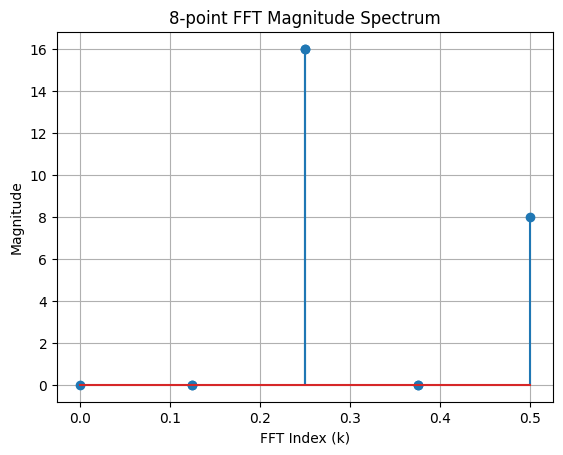

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Given sequence
x = np.array([5, -1, -3, -1, 5, -1, -3, -1])

# Compute 8-point FFT
X = np.fft.fft(x)
frequencies = np.fft.fftfreq(len(x))
print("FFT values:", X)
print("Corresponding frequencies:", frequencies)

# Expected frequencies from x(n) = 4cos(πn/2) + cos(πn)
# cos(πn/2) has frequency 0.25 cycles/sample (FFT index 2)
# cos(πn) has frequency 0.5 cycles/sample (FFT index 4)

# Plot the magnitude spectrum
plt.stem(abs(frequencies), np.abs(X))
plt.xlabel('FFT Index (k)')
plt.ylabel('Magnitude')
plt.title('8-point FFT Magnitude Spectrum')
plt.grid(True)
plt.show()

## Question 2 — Filtering a Signal Using FFT

Filtering is a process in signal processing to remove some unwanted part of the signal within a certain frequency range.

There are low-pass filters, which try to remove all the signal above a certain cut-off frequency, and high-pass filters, which do the opposite.

### (a) High-Pass Filtering

Generate a time-series signal with mixed sine waves at frequencies of 1, 4, and 7 Hz.

Using FFT, apply a high-pass filter to this signal at 6 Hz.

1. Plot the original and filtered signals.
2. Plot the FFT amplitude before and after filtering.

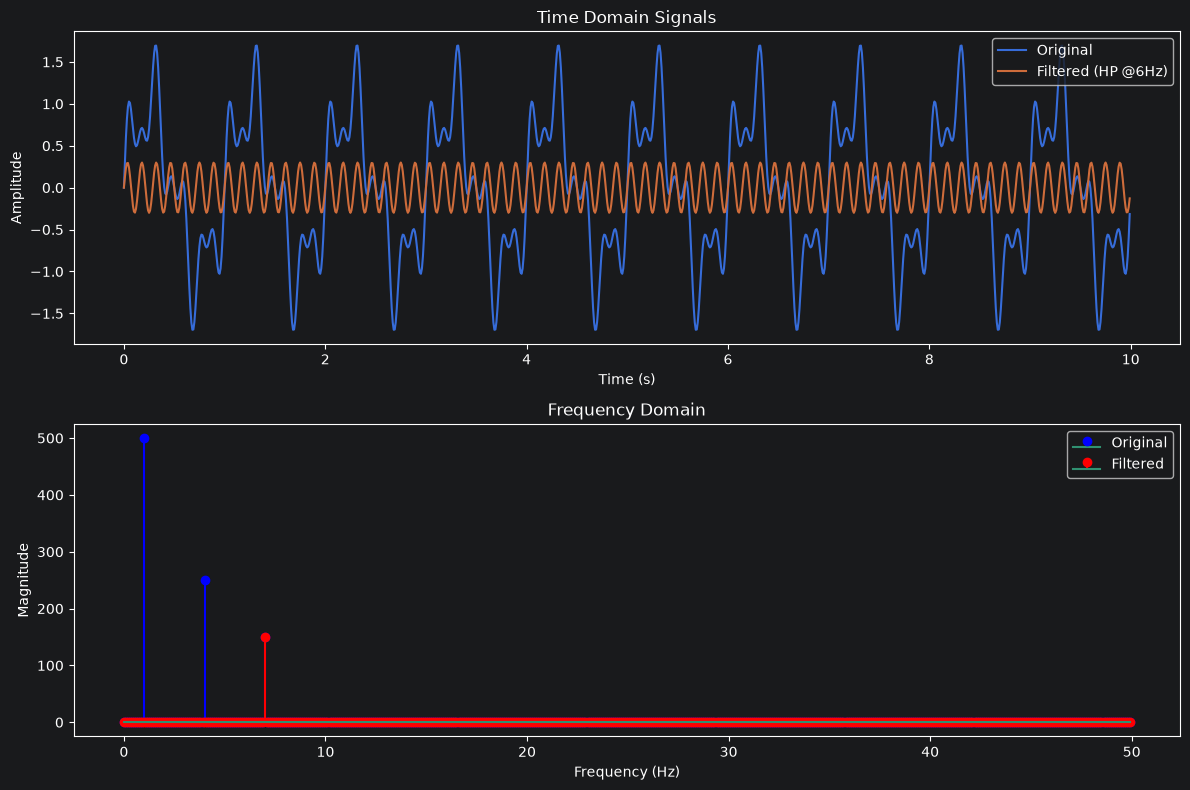

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
fs = 100  # Sampling frequency (Hz)
T = 1.0 / fs
N = 1000  # Number of samples
t = np.linspace(0, N*T, N, endpoint=False)

# Create signal with 1Hz, 4Hz, and 7Hz components
x = np.sin(2*np.pi*1*t) + 0.5*np.sin(2*np.pi*4*t) + 0.3*np.sin(2*np.pi*7*t)

# Compute FFT
X = np.fft.fft(x)
freqs = np.fft.fftfreq(N, T)

# High-pass filter (remove frequencies below 6Hz)
cutoff = 6  # Hz
X_filtered = X.copy()
X_filtered[np.abs(freqs) < cutoff] = 0

# Inverse FFT to get filtered signal
x_filtered = np.fft.ifft(X_filtered).real

# Plotting
plt.figure(figsize=(12, 8))

# Original and filtered signals
plt.subplot(2, 1, 1)
plt.plot(t, x, label='Original')
plt.plot(t, x_filtered, label='Filtered (HP @6Hz)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.title('Time Domain Signals')

# FFT magnitudes
plt.subplot(2, 1, 2)
plt.stem(freqs[:N//2], np.abs(X)[:N//2], 'b', markerfmt='bo', label='Original')
plt.stem(freqs[:N//2], np.abs(X_filtered)[:N//2], 'r', markerfmt='ro', label='Filtered')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.legend()
plt.title('Frequency Domain')

plt.tight_layout()
plt.show()

## Question 4 — Diffraction Using FFT

Light with wavelength $\lambda$ is incident on a single slit with width $w$, gets diffracted, and falls on a screen at a distance $f$.

The intensity of the diffraction pattern on the screen, at a distance $x$ from the central point of the screen, is given by

$$
I(x)=\left|
\int_{-w/2}^{w/2}
q(u)e^{i2\pi xu/(\lambda f)}\,du
\right|^2.
$$

### (a) Single-Slit Diffraction

Write a Python program that uses FFT to calculate the diffraction pattern of a single slit, where

$$
q(u)=1,
$$

with slit width

$$
w=10\,\mu\mathrm{m}.
$$

Use

$$
\lambda=500\,\mathrm{nm},\qquad f=1\,\mathrm{m}.
$$

Plot the intensity pattern as a function of $x$.

### (b) Double-Slit Diffraction

Repeat the same procedure, but for a double slit of width

$$
w=10\,\mu\mathrm{m}
$$

and separation

$$
60\,\mu\mathrm{m}.
$$

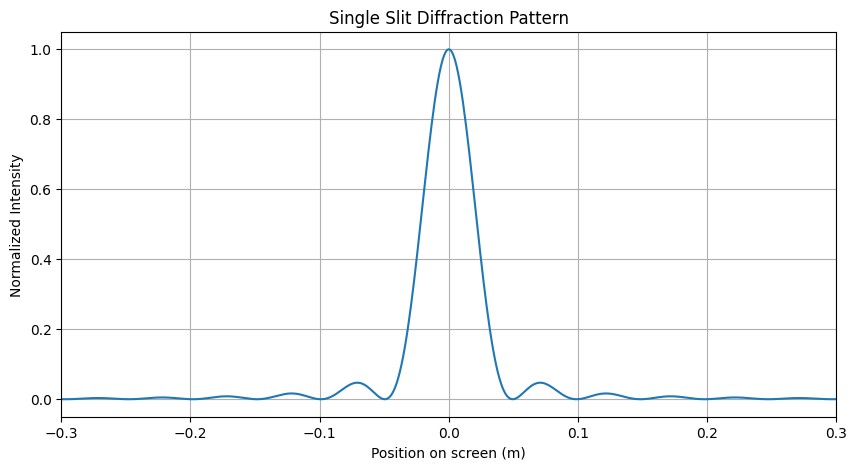

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
w = 10e-6  # slit width (m)
lambda_ = 500e-9  # wavelength (m)
f = 1.0  # distance to screen (m)

# Simulation parameters
N = 4096  # number of samples
du = w / 100  # sampling interval in slit plane
u = np.arange(-N//2, N//2) * du  # slit coordinates
# Create single slit transmission function
q = np.zeros_like(u, dtype=complex)
q[np.abs(u) <= w/2] = 1 + 0j  # unity transmission within slit
# Compute diffraction pattern using FFT
# We need to handle the phase factors carefully
x = np.fft.fftshift(np.fft.fftfreq(N, du)) * lambda_ * f
I = np.abs(np.fft.fftshift(np.fft.fft(np.fft.ifftshift(q))))**2
I = I / np.max(I)  # normalize intensity

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, I)
plt.xlabel('Position on screen (m)')
plt.ylabel('Normalized Intensity')
plt.title('Single Slit Diffraction Pattern')
plt.xlim([-0.3,0.3]) # show ±1 cm of the pattern
plt.grid(True)
plt.show()

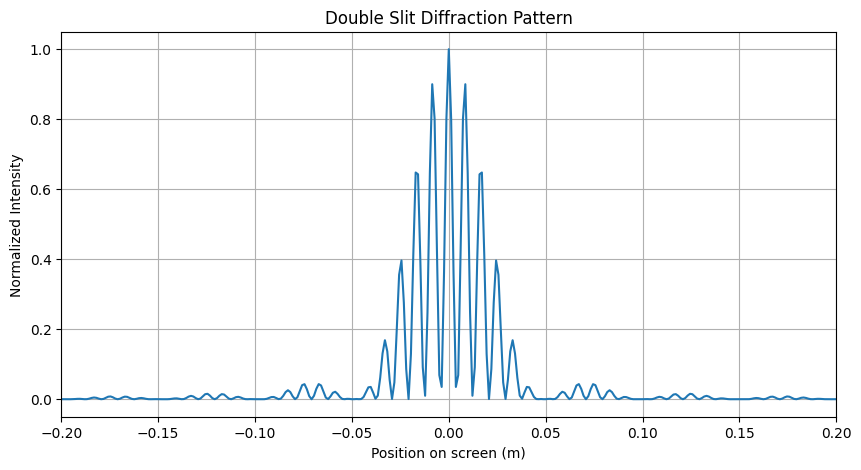

In [4]:
# Parameters for double slit
separation = 60e-6  # separation between slits (m)

# Create double slit transmission function
q_double = np.zeros_like(u, dtype=complex)
slit_centers = [-separation/2, separation/2]

for center in slit_centers:
    slit_start = center - w/2
    slit_end = center + w/2
    q_double[(u >= slit_start) & (u <= slit_end)] = 1 + 0j

# Compute diffraction pattern using FFT
I_double = np.abs(np.fft.fftshift(np.fft.fft(np.fft.ifftshift(q_double))))**2
I_double = I_double / np.max(I_double)  # normalize intensity

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, I_double)
plt.xlabel('Position on screen (m)')
plt.ylabel('Normalized Intensity')
plt.title('Double Slit Diffraction Pattern')
plt.xlim([-0.2, 0.2])  # show ±1 cm of the pattern
plt.grid(True)
plt.show()